We first import the necessary modules and classes and load the data using ```pd.read_csv(...)```. We also do some data-preprocessing where we reset the index, sort the DataFrame according to the battery ID and cycle index and where we transform the battery ID column such that it is easier to work with.
We also collect the different chemistry types, climate zones, usage strategies and degradation statuses.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

g = lambda x: int(x.split('-')[-1])

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)

df2 = df.join(meta[["climate_zone", "chemistry", "usage_strategy"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()

df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))
usage_strategies = list(set(df2["usage_strategy"]))

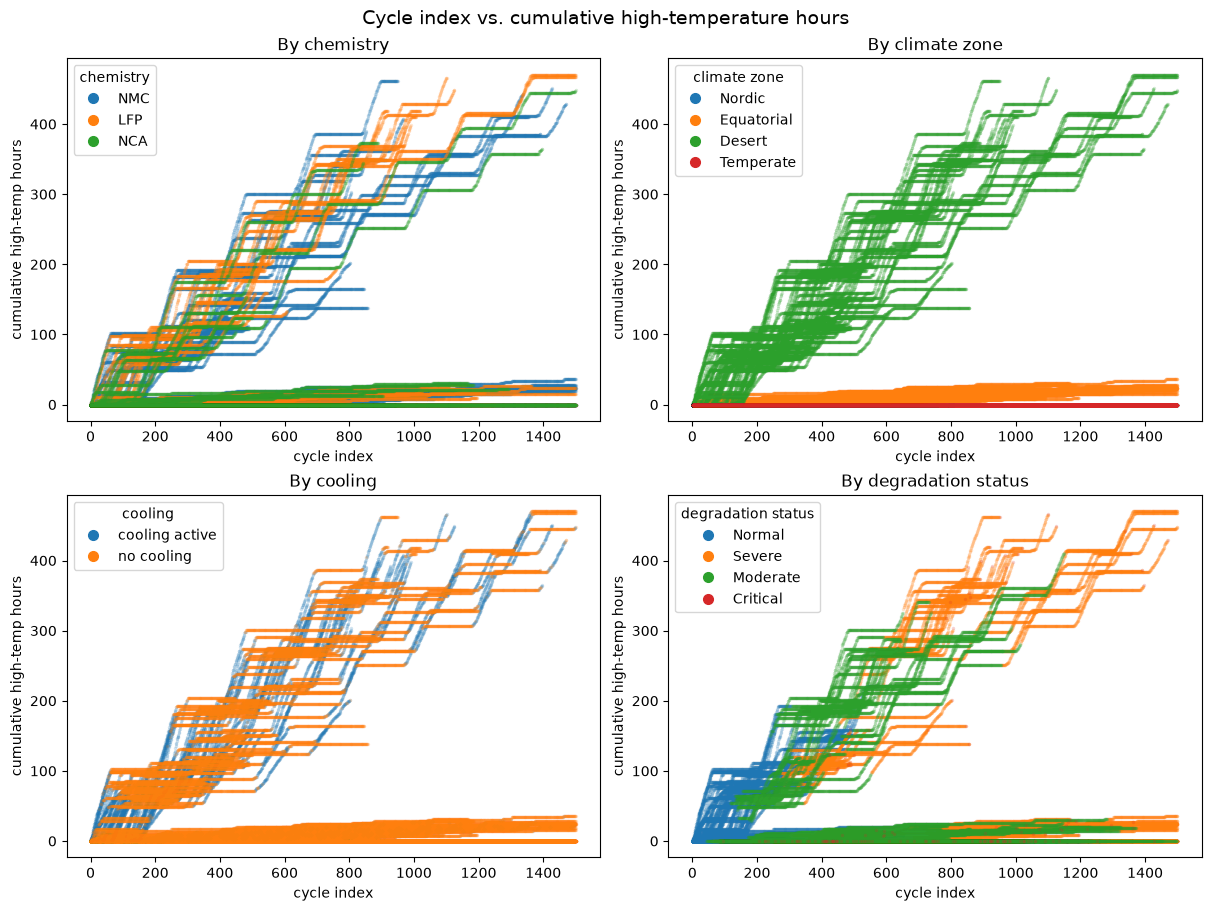

In [4]:
# def add_color_legend(a, color_map, title=None):
#     handles = [Line2D([0], [0], color=c, lw=2, label=str(k)) for k, c in color_map.items()]
#     a.legend(handles=handles, title=title, loc="upper left")

# fig, ax = plt.subplots(2,2, figsize=(10, 12), layout="constrained")

# # by material
# mat_colors = {m: f"C{i}" for i, m in enumerate(materials)}
# for m in materials:
#     x = df2[df2["chemistry"] == m]
#     for bi in battery_ids:
#         y = x[x["battery_id"] == bi].sort_values("cycle_index")
#         ax[0,0].plot(y["cycle_index"], y["cumulative_high_temp_hours"],
#                    color=mat_colors[m], marker="o", markersize=1)
# add_color_legend(ax[0,0], mat_colors, title="chemistry")

# # by climate zone
# climate_colors = {m: f"C{i}" for i, m in enumerate(climate_zones)}
# for m in climate_zones:
#     x = df2[df2["climate_zone"] == m]
#     for bi in battery_ids:
#         y = x[x["battery_id"] == bi].sort_values("cycle_index")
#         ax[0,1].plot(y["cycle_index"], y["cumulative_high_temp_hours"],
#                    color=climate_colors[m], marker="o", markersize=1)
# add_color_legend(ax[0,1], climate_colors, title="climate zone")

# # by cooling
# cooling_colors = {"cooling active": "C0", "no cooling": "C1"}
# for bi in battery_ids:
#     x = df2[df2["battery_id"] == bi].sort_values("cycle_index")
#     x1 = x[x["cooling_active"] == True]
#     x2 = x[x["cooling_active"] == False]
#     ax[1,0].plot(x1["cycle_index"], x1["cumulative_high_temp_hours"],
#                color=cooling_colors["cooling active"], marker="o", markersize=1)
#     ax[1,0].plot(x2["cycle_index"], x2["cumulative_high_temp_hours"],
#                color=cooling_colors["no cooling"], marker="o", markersize=1)
# add_color_legend(ax[1,0], cooling_colors, title="cooling")

# # by degradation status
# degradation_colors = {m: f"C{i}" for i, m in enumerate(labels)}
# for m in labels:
#     x = df2[df2["degradation_status"] == m]
#     for bi in battery_ids:
#         y = x[x["battery_id"] == bi].sort_values("cycle_index")
#         ax[1,1].plot(y["cycle_index"], y["cumulative_high_temp_hours"],
#                    color=degradation_colors[m], marker="o", markersize=1)
# add_color_legend(ax[1,1], degradation_colors, title="degradation status")

# ax[0,0].set_title("cycle index to cumulative temperature hours, by material")
# ax[0,1].set_title("cycle index to cumulative temperature hours, by climate")
# ax[1,0].set_title("cycle index to cumulative temperature hours, by cooling")
# ax[1,1].set_title("cycle index to cumulative temperature hours, by degradation status")

# plt.show()


import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def scatter_by(ax, df, group_col, groups, title, legend_title, names=None):
    colors = {g: f"C{i}" for i, g in enumerate(groups)}
    for g in groups:
        sub = df[df[group_col] == g]
        ax.scatter(sub["cycle_index"], sub["cumulative_high_temp_hours"],
                   color=colors[g], s=6, alpha=0.2, linewidths=0)
    handles = [Line2D([0], [0], marker="o", linestyle="", color=c, markersize=7,
                      label=(names[g] if names else str(g)))
               for g, c in colors.items()]
    ax.legend(handles=handles, title=legend_title, loc="upper left")
    ax.set_title(title)
    ax.set_xlabel("cycle index")
    ax.set_ylabel("cumulative high-temp hours")

fig, ax = plt.subplots(2, 2, figsize=(12, 9), layout="constrained")

scatter_by(ax[0, 0], df2, "chemistry", materials, "By chemistry", "chemistry")
scatter_by(ax[0, 1], df2, "climate_zone", climate_zones, "By climate zone", "climate zone")
scatter_by(ax[1, 0], df2, "cooling_active", [True, False], "By cooling", "cooling",
           names={True: "cooling active", False: "no cooling"})
scatter_by(ax[1, 1], df2, "degradation_status", labels, "By degradation status", "degradation status")

fig.suptitle("Cycle index vs. cumulative high-temperature hours", fontsize=14)
plt.show()

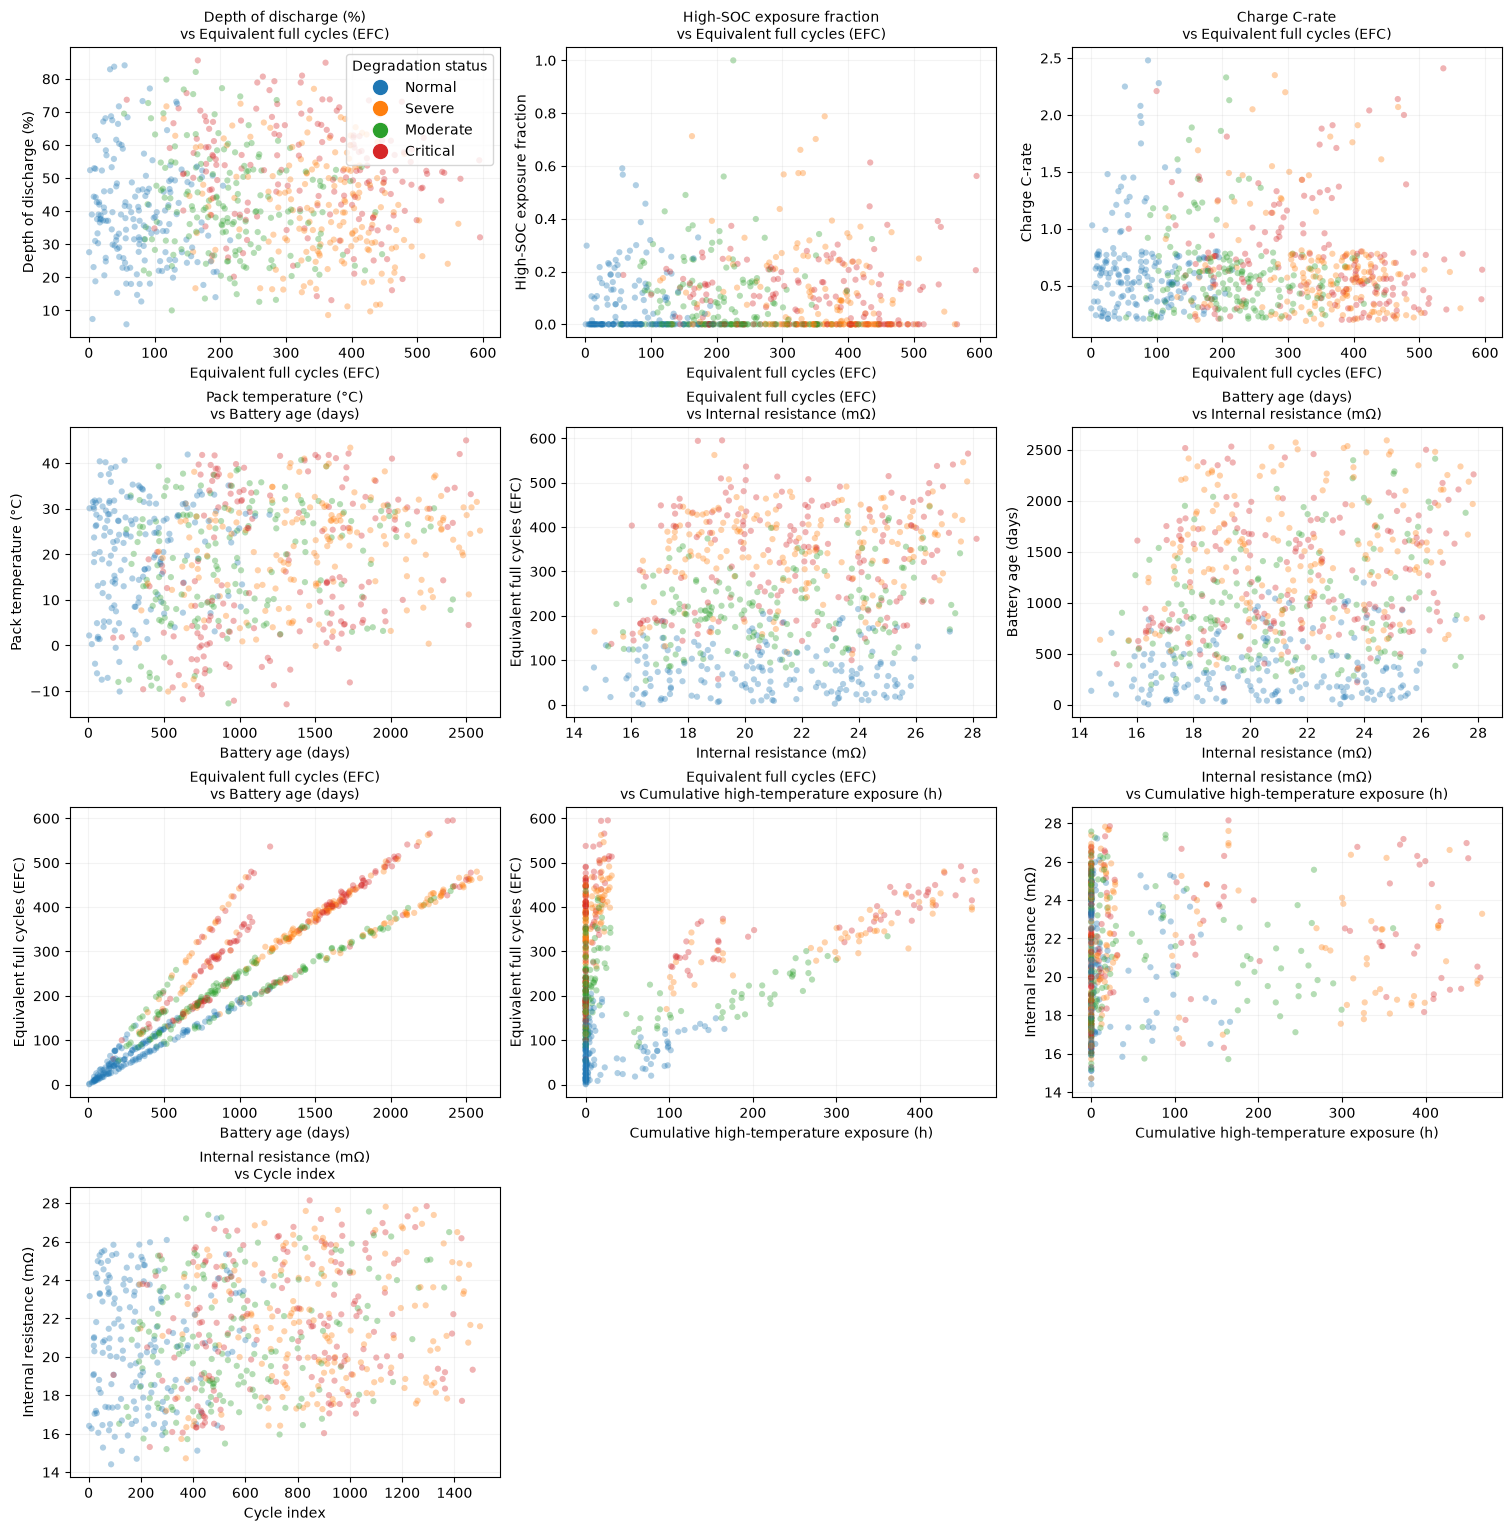

In [6]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Each tuple is (x-axis, y-axis).
variables = [
    # Operating conditions versus accumulated usage
    ("equivalent_full_cycles", "depth_of_discharge_pct"),
    ("equivalent_full_cycles", "high_soc_exposure_fraction"),
    ("equivalent_full_cycles", "charge_c_rate"),
    ("battery_age_days", "pack_temp_c"),

    # Accumulated usage, age, and health indicators
    ("internal_resistance_mOhm", "equivalent_full_cycles"),
    ("internal_resistance_mOhm", "battery_age_days"),
    ("battery_age_days", "equivalent_full_cycles"),
    ("cumulative_high_temp_hours", "equivalent_full_cycles"),
    ("cumulative_high_temp_hours", "internal_resistance_mOhm"),
    ("cycle_index", "internal_resistance_mOhm"),
]


# Use your existing label order.
labels = list(labels)

palette = {
    label: f"C{i % 10}"
    for i, label in enumerate(labels)
}


# Take the same number of rows from each non-empty class.
# Unlike a separate min(1500, len(subset)) for each class,
# this produces an exactly balanced visualization sample.
class_counts = (
    df2.loc[df2["degradation_status"].isin(labels), "degradation_status"]
       .value_counts()
)

if class_counts.empty:
    raise ValueError("No rows match the supplied degradation-status labels.")

n_per_class = min(1500, int(class_counts.min()))

parts = []
for label in labels:
    subset = df2.loc[df2["degradation_status"].eq(label)]

    if subset.empty:
        continue

    parts.append(
        subset.sample(n=n_per_class, random_state=42)
    )

# Shuffle so no single class is consistently drawn on top.
plot_df = (
    pd.concat(parts)
      .sample(frac=1, random_state=42)
)


# Optional: more readable axis labels.
axis_labels = {
    "equivalent_full_cycles": "Equivalent full cycles (EFC)",
    "depth_of_discharge_pct": "Depth of discharge (%)",
    "high_soc_exposure_fraction": "High-SOC exposure fraction",
    "charge_c_rate": "Charge C-rate",
    "battery_age_days": "Battery age (days)",
    "pack_temp_c": "Pack temperature (°C)",
    "internal_resistance_mOhm": "Internal resistance (mΩ)",
    "cumulative_high_temp_hours": "Cumulative high-temperature exposure (h)",
    "cycle_index": "Cycle index",
}


# Create enough panels for any number of variable pairs.
ncols = 3
nrows = math.ceil(len(variables) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 3.8 * nrows),
    layout="constrained",
    squeeze=False
)


for ax, (x, y) in zip(axes.flat, variables):
    # Remove missing values separately for each pair.
    valid = plot_df[[x, y]].notna().all(axis=1)
    subset = plot_df.loc[valid]

    ax.scatter(
        subset[x],
        subset[y],
        c=subset["degradation_status"].map(palette),
        s=20,
        alpha=0.35,
        linewidths=0
    )

    ax.set_xlabel(axis_labels.get(x, x))
    ax.set_ylabel(axis_labels.get(y, y))
    ax.set_title(
        f"{axis_labels.get(y, y)}\nvs {axis_labels.get(x, x)}",
        fontsize=10
    )
    ax.grid(alpha=0.15)


# Hide unused panels.
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)


# Opaque legend markers remain readable despite transparent points.
handles = [
    Line2D(
        [], [],
        linestyle="",
        marker="o",
        markersize=10,
        color=palette[label],
        label=label
    )
    for label in labels
    if label in plot_df["degradation_status"].unique()
]

axes.flat[0].legend(
    handles=handles,
    title="Degradation status",
    loc="best"
)

plt.show()

In [7]:
nonnormal = df2[df2["degradation_status"] != "Normal"]
x = nonnormal.groupby("battery_id").agg(
    min_cycle_idx=("cycle_index", "min"),
    age_when_reached=("battery_age_days", "min"),
    mean_ambient_temp=("ambient_temp_c", "mean"),
    mean_pack_temp=("pack_temp_c", "mean"), 
    high_temp_hours_before=("cumulative_high_temp_hours", "min"),
    mean_charge=("charge_c_rate", "mean"),
    mean_discharge=("discharge_c_rate", "mean"),
    mean_cooling_active=("cooling_active", "mean")
)
x

,min_cycle_idx,age_when_reached,mean_ambient_temp,mean_pack_temp,high_temp_hours_before,mean_charge,mean_discharge,mean_cooling_active
battery_id,,,,,,,,
1,347,625.2,14.406047,14.705357,0.0,0.498864,0.655723,0.000000
2,289,512.9,4.547577,4.826726,0.0,0.496432,0.658040,0.000000
3,202,352.7,24.055802,24.938404,56.4,1.067975,1.460691,0.246914
4,225,412.2,4.987719,5.252590,0.0,0.495049,0.646004,0.000000
5,330,601.2,4.619025,4.845079,0.0,0.501336,0.653129,0.000000
...,...,...,...,...,...,...,...,...
196,231,394.9,3.497572,3.669643,0.0,0.496380,0.656623,0.000000
197,575,1038.3,14.480087,14.643249,0.0,0.493106,0.655790,0.000000
198,420,774.7,25.452279,25.682385,140.0,0.506689,0.658485,0.273458


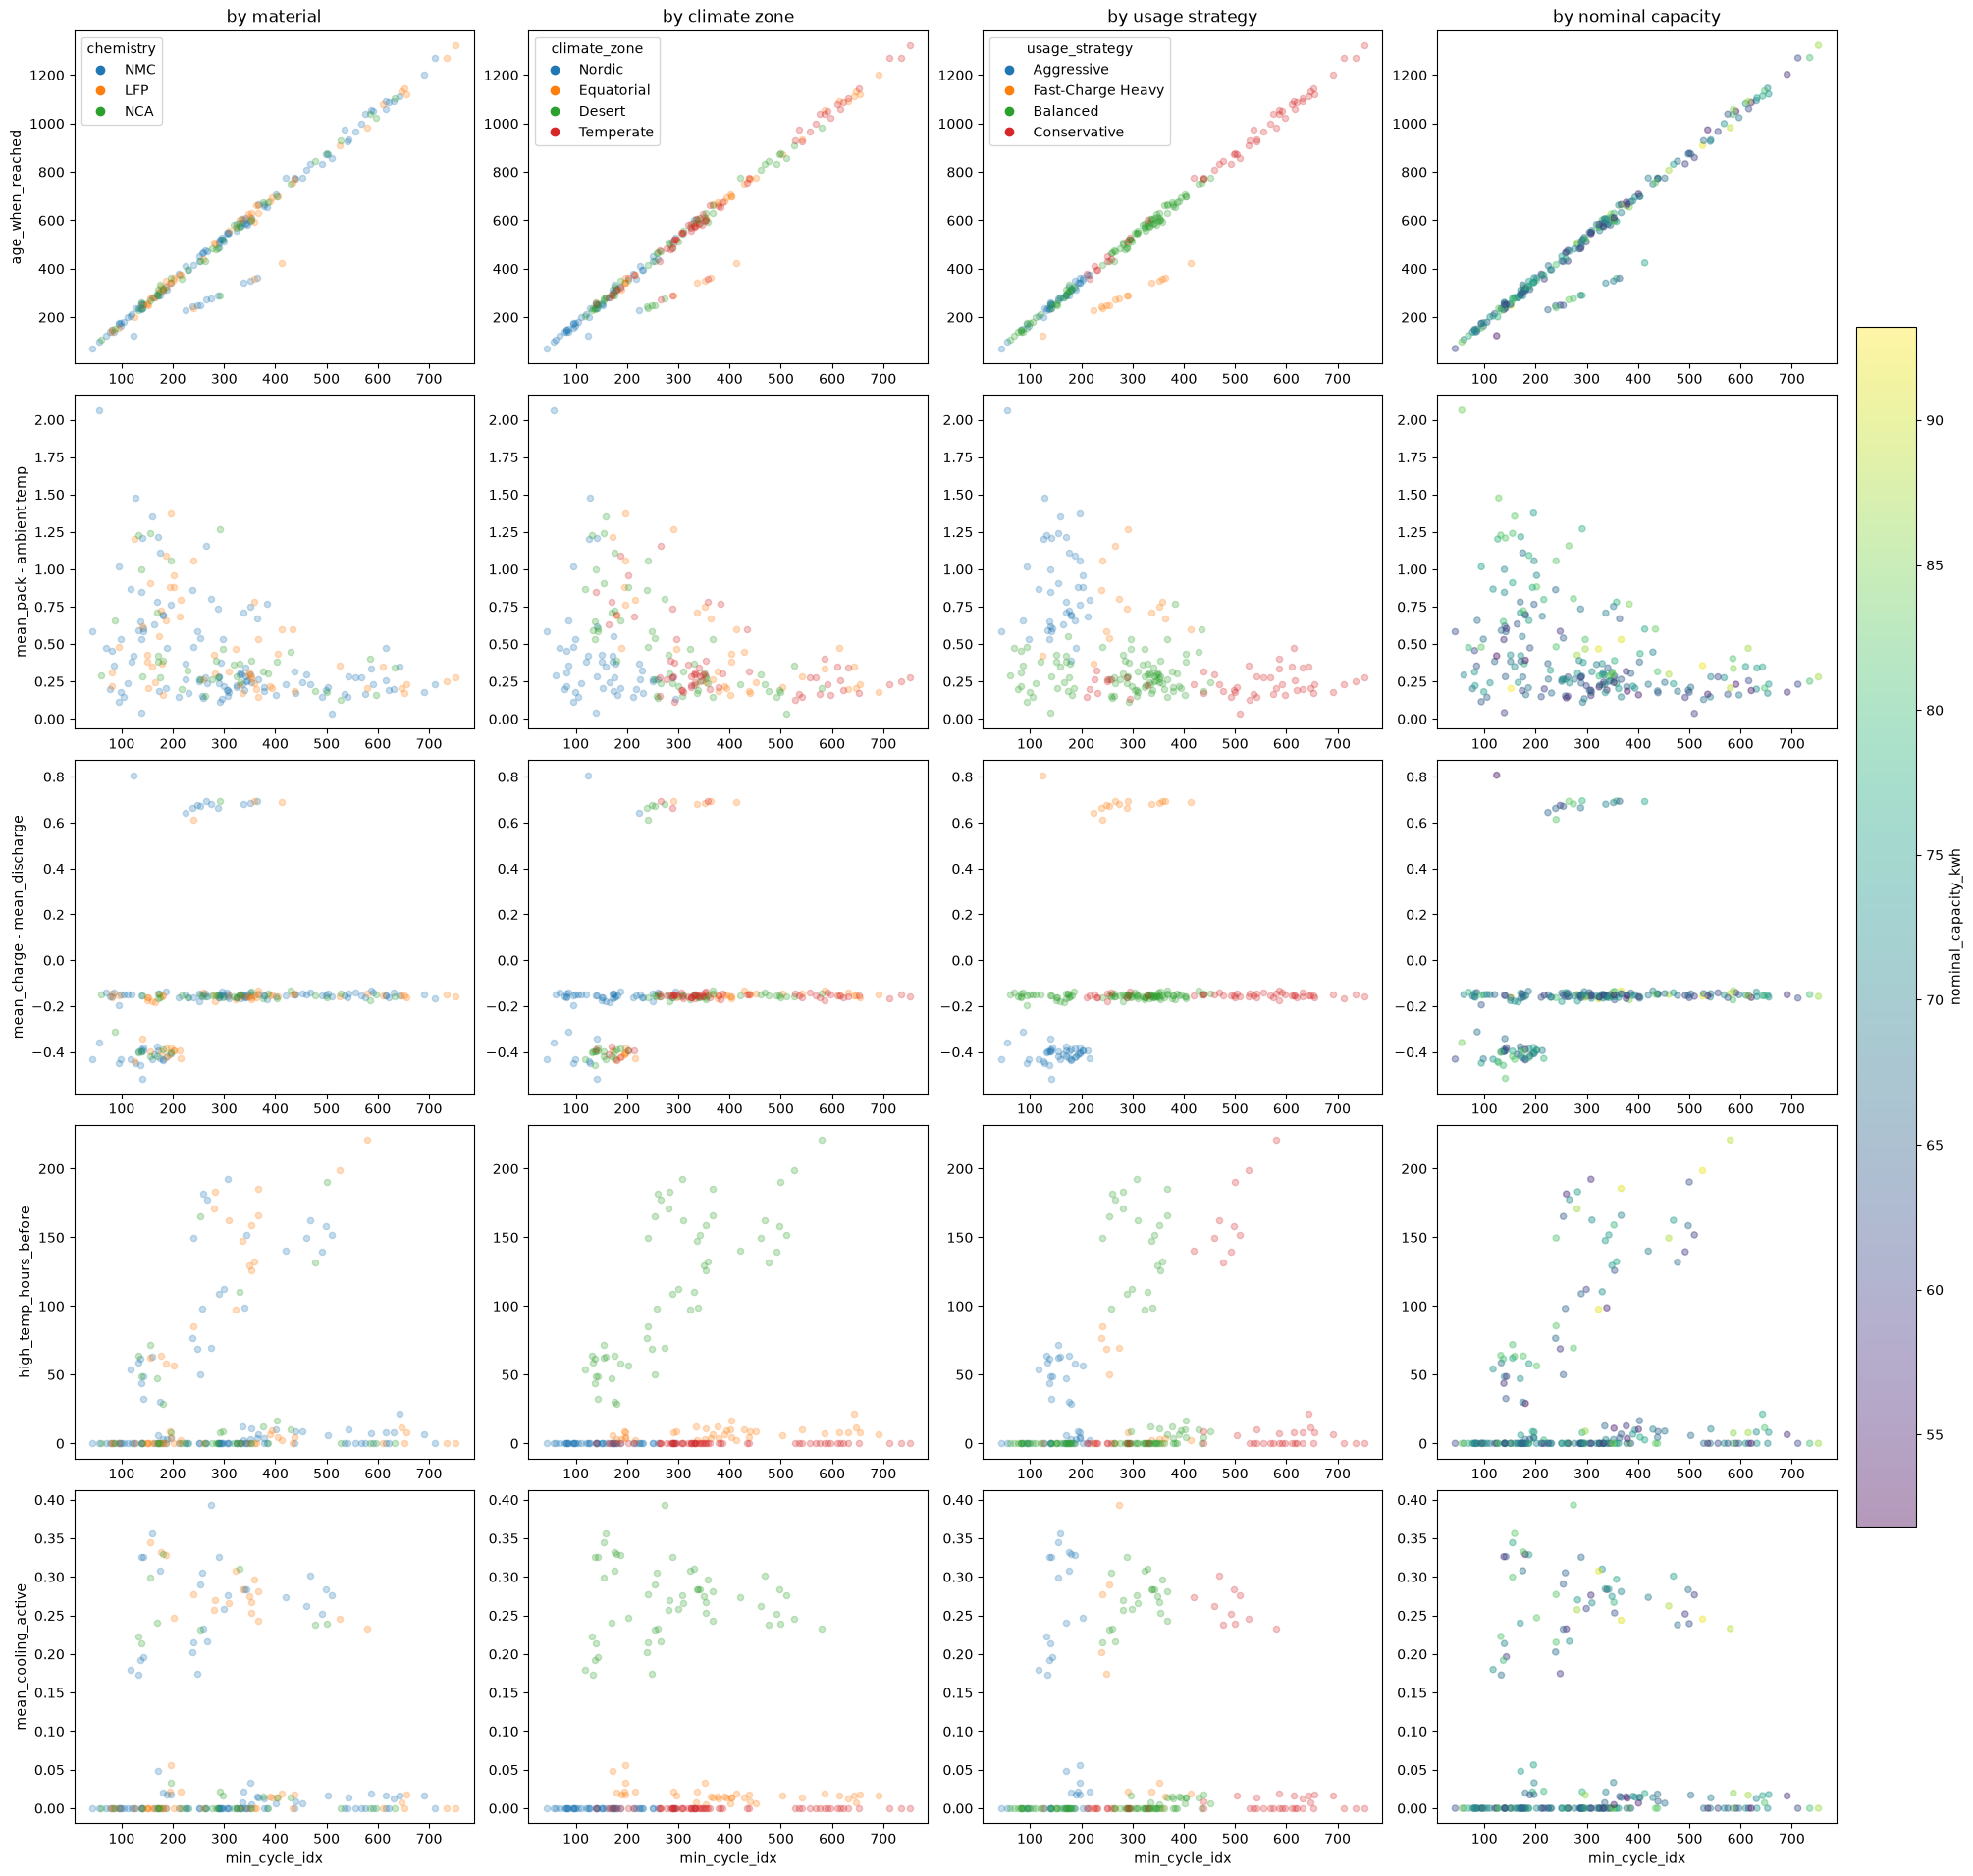

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

metrics = [
    ("age_when_reached",             lambda d: d["age_when_reached"]),
    ("mean_pack - ambient temp",     lambda d: d["mean_pack_temp"] - d["mean_ambient_temp"]),
    ("mean_charge - mean_discharge", lambda d: d["mean_charge"] - d["mean_discharge"]),
    ("high_temp_hours_before",       lambda d: d["high_temp_hours_before"]),
    ("mean_cooling_active",          lambda d: d["mean_cooling_active"]),
]

# categorical columns: (meta column, groups, title)
columns = [
    ("chemistry",      materials,        "by material"),
    ("climate_zone",   climate_zones,    "by climate zone"),
    ("usage_strategy", usage_strategies, "by usage strategy"),
]

nrows = len(metrics)
ncols = len(columns) + 1          # +1 for the continuous capacity column
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows),
                         layout="constrained", squeeze=False)

# --- categorical columns: one color per group, with legend ---
for j, (meta_col, groups, title) in enumerate(columns):
    color_map = {g: f"C{k}" for k, g in enumerate(groups)}

    for g in groups:
        ids = meta.loc[meta[meta_col] == g, "battery_id"]
        y = x[x.index.isin(ids)]
        for i, (ylabel, fn) in enumerate(metrics):
            axes[i, j].scatter(y["min_cycle_idx"], fn(y),
                               color=color_map[g], s=20, alpha=0.25)

    axes[0, j].set_title(title)
    handles = [Line2D([0], [0], marker="o", linestyle="none", color=c, label=str(g))
               for g, c in color_map.items()]
    axes[0, j].legend(handles=handles, title=meta_col, loc="best")

# last column: continuous nominal capacity, colormap + colorbar
j = ncols - 1
capacity = meta.set_index("battery_id")["nominal_capacity_kwh"]
cap = x.index.map(capacity) # capacity of each row's battery (x is indexed by battery_id)
vmin, vmax = capacity.min(), capacity.max() # same color scale in every row

for i, (ylabel, fn) in enumerate(metrics):
    sc = axes[i, j].scatter(x["min_cycle_idx"], fn(x), c=cap, cmap="viridis",
                            vmin=vmin, vmax=vmax, s=20, alpha=0.4)

axes[0, j].set_title("by nominal capacity")
fig.colorbar(sc, ax=axes[:, j], label="nominal_capacity_kwh", shrink=0.8)

# labels shared by all columns
for j in range(ncols):
    axes[-1, j].set_xlabel("min_cycle_idx")
for i, (ylabel, _) in enumerate(metrics):
    axes[i, 0].set_ylabel(ylabel)

plt.show()